In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
    
from sklearn.impute import SimpleImputer

In [2]:
df = pd.read_csv("shop_smart_ecommerce.csv")

In [9]:
df.head()
df.info()
df.isnull().sum()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [10]:
# Analysis EDA

# month_cnt = df["Month"].value_counts()
# ax = sns.barplot(month_cnt)
# ax.bar_label(ax.containers[0])

# visitorType_cnt = df["VisitorType"].value_counts()
# ax = sns.barplot(visitorType_cnt)
# ax.bar_label(ax.containers[0])




In [11]:
# Encoder
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [12]:
# for LabelEncoder -> Use for ordinal data
le = LabelEncoder()
df["Weekend"] = le.fit_transform(df["Weekend"])
df["Revenue"] = le.fit_transform(df["Revenue"])

In [14]:
# Convert month names to numbers
month_map = {
    "Jan": 1,
    "Feb": 2,
    "Mar": 3,
    "Apr": 4,
    "May": 5,
    "Jun": 6,
    "Jul": 7,
    "Aug": 8,
    "Sep": 9,
    "Oct": 10,
    "Nov": 11,
    "Dec": 12
}

df["Month"] = df["Month"].map(month_map)

# OneHotEncode nominal columns
cols = ["VisitorType"]

ohe = OneHotEncoder(
    drop="first",
    sparse_output=False,
    handle_unknown="ignore"
)

encoded = ohe.fit_transform(df[cols])

encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(cols),
    index=df.index
)

# Cyclical encoding
df["month_sin"] = np.sin(2 * np.pi * df["Month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["Month"] / 12)

# Final dataframe
df = pd.concat(
    [
        df.drop(columns=cols + ["Month"]),
        encoded_df
    ],
    axis=1
)

df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,Browser,Region,TrafficType,Weekend,Revenue,month_sin,month_cos,VisitorType_Other,VisitorType_Returning_Visitor
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,1,1,1,1,0,0,0.866025,0.5,0.0,1.0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,2,2,1,2,0,0,0.866025,0.5,0.0,1.0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,4,1,9,3,0,0,0.866025,0.5,0.0,1.0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,3,2,2,4,0,0,0.866025,0.5,0.0,1.0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,3,3,1,4,1,0,0.866025,0.5,0.0,1.0


<Axes: >

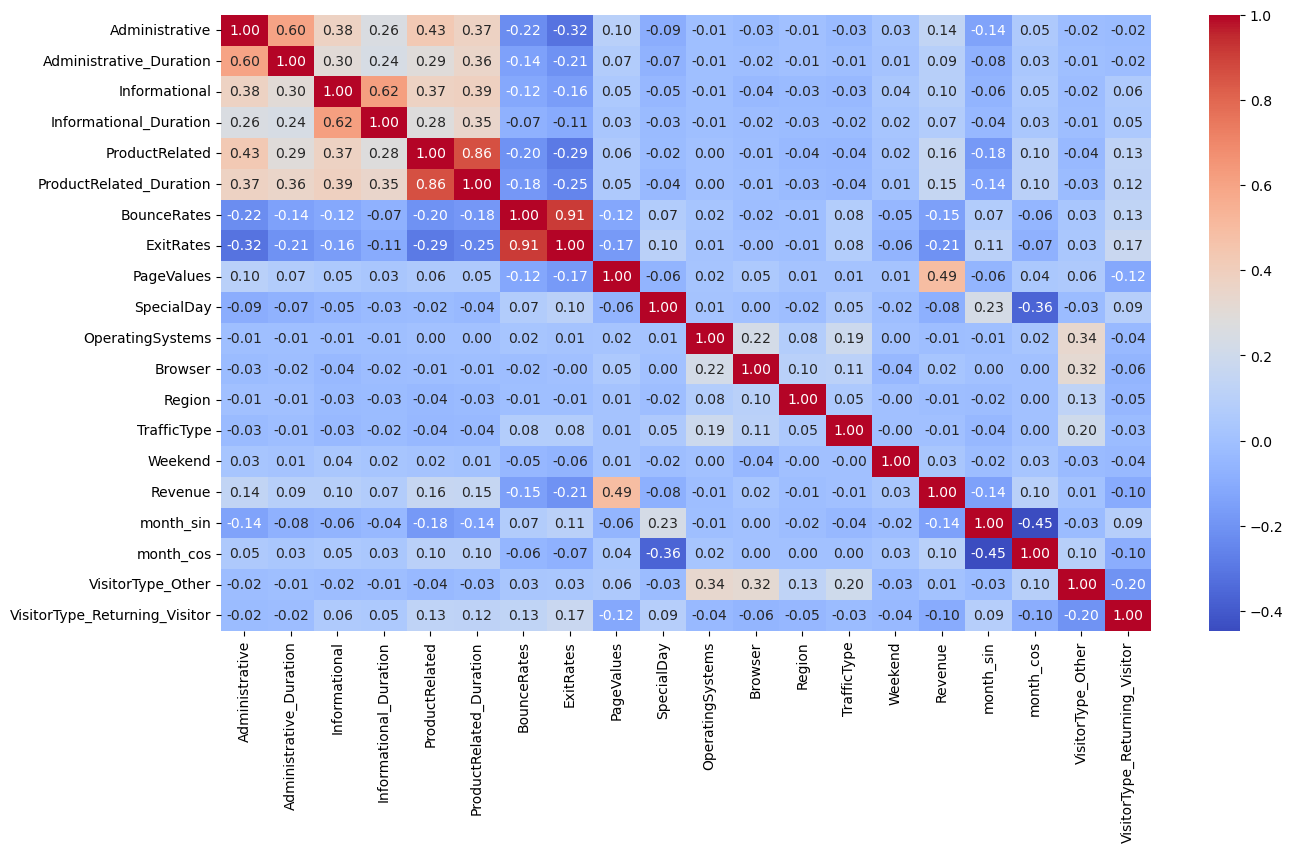

In [17]:
#Corelation map
num_cols = df.select_dtypes(include="number")
corr_matrix = num_cols.corr()

plt.figure(figsize=(15,8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

In [18]:
num_cols.corr()["Revenue"].sort_values(ascending=False)

Revenue                          1.000000
PageValues                       0.492569
ProductRelated                   0.158538
ProductRelated_Duration          0.152373
Administrative                   0.138917
month_cos                        0.101131
Informational                    0.095200
Administrative_Duration          0.093587
Informational_Duration           0.070345
Weekend                          0.029295
Browser                          0.023984
VisitorType_Other                0.007715
TrafficType                     -0.005113
Region                          -0.011595
OperatingSystems                -0.014668
SpecialDay                      -0.082305
VisitorType_Returning_Visitor   -0.103843
month_sin                       -0.144456
BounceRates                     -0.150673
ExitRates                       -0.207071
Name: Revenue, dtype: float64

In [22]:
# Train Test Evaluate
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    f1_score,
    classification_report,
    confusion_matrix
)

In [24]:

# Split data
# -----------------------------
X = df.drop("Revenue", axis=1)
y = df["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# -----------------------------
# Base model
# -----------------------------
dt = DecisionTreeClassifier(
    class_weight="balanced",
    random_state=42
)

# -----------------------------
# Hyperparameter grid
# -----------------------------
param_grid = {
    "max_depth": [4, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5],
    "ccp_alpha": [0.0, 0.0001, 0.001, 0.01]
}

# -----------------------------
# GridSearchCV
# -----------------------------
grid = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1
)

# Train
grid.fit(X_train, y_train)

# -----------------------------
# Best model
# -----------------------------
best_model = grid.best_estimator_

print("Best Parameters:")
print(grid.best_params_)

# -----------------------------
# Predictions
# -----------------------------
y_pred = best_model.predict(X_test)

# -----------------------------
# Evaluation
# -----------------------------
print("\nF1 Score:")
print(f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Fitting 5 folds for each of 180 candidates, totalling 900 fits
Best Parameters:
{'ccp_alpha': 0.01, 'max_depth': 4, 'min_samples_leaf': 1, 'min_samples_split': 2}

F1 Score:
0.6485310119695321

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.89      0.92      2084
           1       0.55      0.78      0.65       382

    accuracy                           0.87      2466
   macro avg       0.76      0.83      0.78      2466
weighted avg       0.89      0.87      0.88      2466


Confusion Matrix:
[[1845  239]
 [  84  298]]


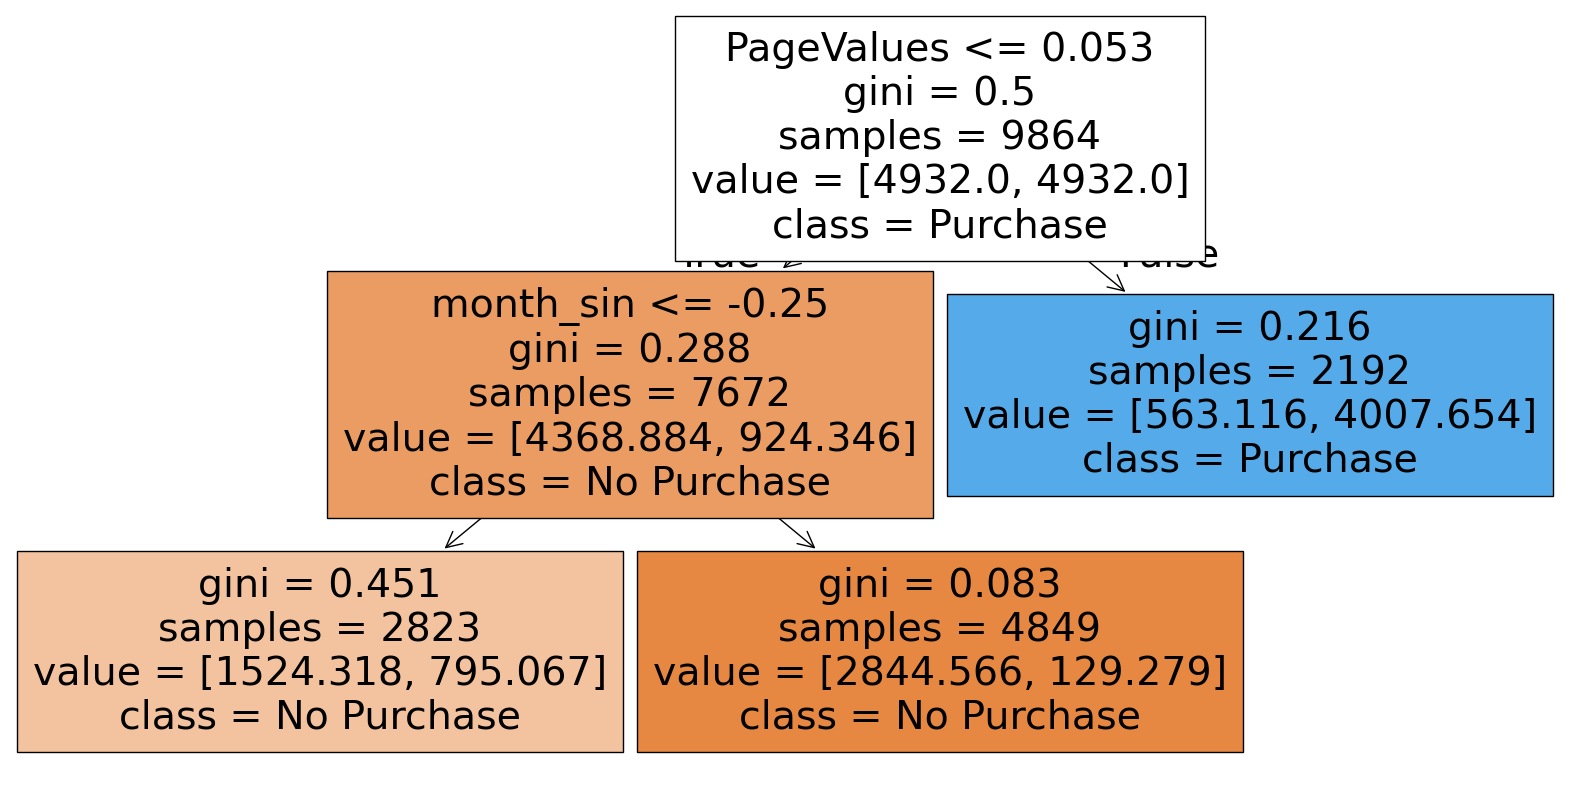

In [26]:
from sklearn import tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20,10))

tree.plot_tree(
    best_model,
    feature_names=X.columns,
    class_names=["No Purchase", "Purchase"],
    filled=True
)

plt.show()